# BIOT 6900 · Module 9 — Notebook 3 (GRADED)
## Clinical NLP on your own disease: build it, then catch the leakage
**Week 9 · Part III · this is the graded assignment**

> **⚠️ SYNTHETIC.** You design a synthetic patient population for a disease of your choice, run the full pipeline on it, and then do the hard part: look at what the model learned and separate genuine early signal from leakage.

You configure your disease's clinical picture (which findings are genuine early signals, which are interventions done to deteriorating patients). The notebook builds a cohort and notes from your choices, extracts features, trains a model, and reports permutation importance. **It also injects two clinical features you did not configure** — you must diagnose each as signal or leakage from the output.

**What is graded (course 60 / 40):** 60% execution (your config is clinically sensible, the notebook runs, the pipeline is correct) and **40% interpretation** (Part D: correctly sorting signal from leakage and defending it). See the assignment sheet for the rubric.

**How to run:** `Kernel → Restart & Run All`. It uses only `pandas` + `scikit-learn`.

## The engine (provided, do not edit)
Run this cell and move on. It defines the assertion engine, the cohort/notes generator, and the model helpers.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure your disease  (TODO)
Replace the EXAMPLE config with **your own disease**. You need:
- 2–3 **signals**: genuine, *early* findings that are **causes** of deterioration (present before things go wrong).
- 2–3 **consequences**: interventions or actions taken *because* a patient is deteriorating. These are your planted leakage.
- For each, give a few **synonyms / abbreviations** (the notes will use them at random, so normalization matters).

Choosing these well is a clinical-reasoning task, and it is graded. A cause belongs in `signals`; a treatment or end-of-life decision belongs in `consequences`.

In [2]:
# ======== EDIT THIS: replace the example with YOUR disease ========
# Disease: severe acute pancreatitis (SAP) managed in the ICU.
# SIGNALS = early findings that drive deterioration, present at/near admission.
#   These are three of the five BISAP components (BUN>25, impaired mental status,
#   SIRS, age>60, pleural effusion); BUN is folded into hemoconcentration.
# CONSEQUENCES = things done TO a patient because they are already deteriorating
#   (organ support, rescue procedures, end-of-life decisions) -> planted leakage.
CONFIG = {
    "disease": "Severe acute pancreatitis (ICU)",
    "signals": {
        "sirs":              ["SIRS", "systemic inflammatory response syndrome", "systemic inflammatory response"],
        "pleural_effusion":  ["pleural effusion", "effusion", "pleural fluid"],
        "hemoconcentration": ["hemoconcentration", "elevated BUN", "high hematocrit"],
    },
    "consequences": {
        "mechanical_ventilation": ["mechanical ventilation", "intubated", "ventilator"],
        "necrosectomy":           ["necrosectomy", "percutaneous drainage", "surgical debridement"],
        "comfort_care":           ["comfort measures only", "cmo", "hospice", "palliative extubation"],
    },
}

SEED = 2034949       # my student-ID number (002034949; leading zeros dropped because Python ints cannot start with 0)
# =================================================================

struct, NOTES = build_world(CONFIG, seed=SEED, N=400)
print("#"*70)
print(f"# SYNTHETIC cohort for: {CONFIG['disease']}")
print(f"# 400 patients, 3 notes each. Mortality prevalence = {struct.died.mean():.2f}")
print("#"*70)
print("Example patient notes:")
for tag, t in zip(["admit ", "day 2 ", "final "], NOTES[0]):
    print(f"  [{tag}] {t}")


######################################################################
# SYNTHETIC cohort for: Severe acute pancreatitis (ICU)
# 400 patients, 3 notes each. Mortality prevalence = 0.23
######################################################################
Example patient notes:
  [admit ] 45F admitted to the ICU. Lactate 1.0, creatinine 0.6.
  [day 2 ] Progress note, hospital day 2.
  [final ] Discharge / final note. Stable for discharge.


## Part B — Extract features  (TODO)
Assemble every concept to extract: your signals, your consequences, and the two injected wildcards. Then run the extractor across all 400 patients.

In [3]:
# the two injected features you did NOT configure are added here for you:
ALL_CONCEPTS = {**CONFIG["signals"], **CONFIG["consequences"], **WILDCARDS}

feat = pd.DataFrame({"subject_id": struct.subject_id})
for name, syns in ALL_CONCEPTS.items():
    feat[name] = [concept_present(syns, NOTES[i]) for i in range(400)]

print("Patients with each concept asserted PRESENT:")
print(feat.drop(columns="subject_id").sum().to_string())

Patients with each concept asserted PRESENT:
sirs                      101
pleural_effusion          100
hemoconcentration          85
mechanical_ventilation     77
necrosectomy               87
comfort_care               77
lactate_not_clearing       89
renal_replacement          71


Sanity check: compare naive keyword counting to assertion-aware counting for one of your signals.

In [4]:
one_signal = list(CONFIG["signals"])[0]
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
aware = int(feat[one_signal].sum())
print(f"{one_signal}:  naive keyword count = {naive}   assertion-aware = {aware}")

sirs:  naive keyword count = 172   assertion-aware = 101


In [5]:
# (added) the same naive-vs-assertion check for ALL three of my signals
for sig, syns in CONFIG["signals"].items():
    naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
    print(f"{sig:18s} naive = {naive:3d}   assertion-aware = {int(feat[sig].sum()):3d}")


sirs               naive = 172   assertion-aware = 101
pleural_effusion   naive = 167   assertion-aware = 100
hemoconcentration  naive = 170   assertion-aware =  85


## Part C — Model and importance  (TODO)
Build the feature matrix, then **declare which of YOUR concepts you planted as leakage**. Do not include the wildcards yet — you have to find those in Part D.

In [6]:
df = struct.merge(feat, on="subject_id")
df["sex_F"] = (df.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
concept_cols = list(ALL_CONCEPTS)
all_cols = struct_cols + concept_cols

# TODO: list the concepts YOU configured as consequences (your planted leakage)
declared_leak = list(CONFIG["consequences"])     # EDIT if you want; by default your consequences

m, sd   = cv_auroc(df, all_cols)
mh, sdh = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"CV AUROC   all features = {m:.3f} ± {sd:.3f}")
print(f"CV AUROC   your declared leakage removed = {mh:.3f} ± {sdh:.3f}")

CV AUROC   all features = 0.922 ± 0.055
CV AUROC   your declared leakage removed = 0.833 ± 0.077


comfort_care              0.049
mechanical_ventilation    0.040
age                       0.032
renal_replacement         0.028
lactate                   0.018
necrosectomy              0.013
lactate_not_clearing      0.010
hemoconcentration         0.008
pleural_effusion          0.007
sex_F                     0.001
sirs                      0.001
creatinine               -0.000


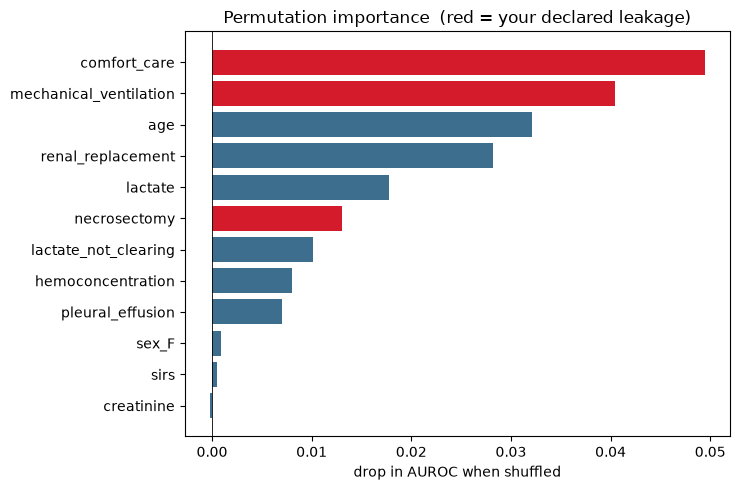

In [7]:
imp = perm_importance(df, all_cols)
print(imp.round(3).to_string())

order = imp.sort_values()
leakset = set(declared_leak)
colors = ["#D41B2C" if c in leakset else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7.5, 5))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = your declared leakage)")
plt.xlabel("drop in AUROC when shuffled"); plt.tight_layout()
plt.savefig("permutation_importance.png", dpi=150)
plt.show()

## Part D — Catch the leakage and interpret  (GRADED, the 40%)
Now the real work. Answer each prompt in the markdown cell that follows it. Use the permutation importance and the AUROC numbers as evidence, and clinical reasoning (cause vs consequence) as the argument.

### D1. Read the importance plot
List the features at the **top** of the permutation-importance ranking. For each, say whether it is genuine early **signal** or **leakage**, and give a one-sentence clinical reason (is it a cause the patient had, or a consequence of them deteriorating?).

> *Your answer:*

Top six features by permutation importance (drop in held-out AUROC when shuffled):

1. **`comfort_care`** (importance 0.049): LEAKAGE. Comfort measures only / hospice is an end-of-life decision made after the team judges the patient is dying; it is basically the outcome written down in advance.
2. **`mechanical_ventilation`** (importance 0.040): LEAKAGE. Intubation is organ support given because respiratory failure has already happened; it marks deterioration rather than predicting it.
3. **`age`** (importance 0.032): SIGNAL. Age is fixed before admission and is a real risk factor for death in pancreatitis (age > 60 is a BISAP point).
4. **`renal_replacement`** (importance 0.028): LEAKAGE (the hidden one, see D2). Dialysis/RRT is started because the kidneys have already failed, and it is documented in the discharge note.
5. **`lactate`** (importance 0.018): SIGNAL. Admission lactate reflects hypoperfusion at presentation, measured before any of the downstream interventions.
6. **`necrosectomy`** (importance 0.013): LEAKAGE. Necrosectomy / percutaneous drainage is a rescue procedure done because necrosis has become infected or the patient is failing, so it is a consequence of deterioration, and it only appears in the final note.

**What the plot says overall:** 3 of the top 4 features are leakage (comfort care, mechanical ventilation, renal replacement), and only age breaks into that group because it is a strong real risk factor. My configured signals (SIRS, pleural effusion, hemoconcentration) sit near the bottom: each one adds a fixed bump to risk, while the leaky features nearly *are* the outcome, so the model leans on them first. The red bars are my declared leakage, but `renal_replacement` is blue and still ranks #4, above admission lactate and above one of my own declared leaks (necrosectomy). That already looks suspicious before D2.

Side note: necrosectomy ranks lower than my other two consequences because it is the least specific one. Mortality with it is 0.45, versus ~0.6 for ventilation and comfort care, since many survivors also get drainage procedures. It is still leakage by its clinical logic even though the model uses it less.


In [8]:
# (added) Evidence for D2: WHEN in the stay is each feature documented, and how does it split by outcome?
# note index 0 = admission, 1 = hospital day 2, 2 = discharge / final note
rows = []
for name, syns in ALL_CONCEPTS.items():
    where = [0, 0, 0]
    for i in range(400):
        for k in range(3):
            if concept_present(syns, [NOTES[i][k]]):
                where[k] += 1
    pos = df[name] == 1
    rows.append({"feature": name,
                 "in_admit_note": where[0], "in_day2_note": where[1], "in_final_note": where[2],
                 "mortality_if_present": round(df.loc[pos, "died"].mean(), 2),
                 "mortality_if_absent":  round(df.loc[~pos, "died"].mean(), 2)})
timing = pd.DataFrame(rows).set_index("feature")
print(f"Baseline mortality = {df.died.mean():.2f}\n")
print(timing.to_string())


Baseline mortality = 0.23

                        in_admit_note  in_day2_note  in_final_note  mortality_if_present  mortality_if_absent
feature                                                                                                      
sirs                              101             0              0                  0.24                 0.23
pleural_effusion                  100             0              0                  0.34                 0.20
hemoconcentration                  85             0              0                  0.27                 0.23
mechanical_ventilation              0             0             77                  0.66                 0.13
necrosectomy                        0             0             87                  0.45                 0.18
comfort_care                        0             0             77                  0.62                 0.14
lactate_not_clearing               89             0              0                  0.39     

### D2. Hunt the hidden leak
Your 'declared leakage removed' AUROC is probably still high. That is a clue you missed a leak. Two features were injected that you did not configure: **`lactate_not_clearing`** and **`renal_replacement`**. From the importance plot and clinical reasoning, classify each as signal or leakage, and justify. Then add any you judge to be leakage to the set below and re-run.

> *Your answer:*

**`renal_replacement` = LEAKAGE.**
- *Clinical reasoning:* dialysis / renal replacement therapy is an intervention. You start it because the patient has already developed severe AKI, fluid overload or refractory acidosis, i.e. because they are deteriorating. It is the same category as intubation, just for the kidney.
- *Timing evidence (table above):* it is documented 0 times in admission notes and 71 times in the final note, so it is only known at the end of the stay, after the outcome is already happening.
- *Outcome evidence:* mortality is 0.61 vs 0.16 (present vs absent), and it ranked #4 in importance, up with my declared consequences. That is the behaviour of a feature restating the outcome.
- The few survivors who have it are "brief dialysis for contrast, since stopped" notes. Note the engine still tags that as *present* (there is no "since stopped" trigger), which is another reason not to trust this column as a clean feature.

**`lactate_not_clearing` = SIGNAL.**
- *Clinical reasoning:* failure to clear lactate despite resuscitation is a measurement of the patient's physiology (ongoing hypoperfusion / shock), not a decision the team made. It is a recognised early warning in the first hours of care, and it is exactly the kind of hedge a clinician writes in a note before any code exists.
- *Timing evidence:* it appears 89 times in admission notes and 0 times in the final note, so it is available at the time a prediction would be made.
- *Outcome evidence:* mortality is 0.39 vs 0.19: a real but partial lift (most patients with it still survive), which is what a risk factor looks like, unlike a leak where presence almost guarantees the outcome. In the honest model it stays important (importance 0.037, rank #3), so it carries signal on its own and is not just riding on leakage.

**Decision:** `final_leak = declared_leak + ["renal_replacement"]` (cell below). `lactate_not_clearing` stays in the model.


In [9]:
# TODO: your FINAL leak set = your declared leakage + any wildcard you caught
# D2 decision: renal_replacement = LEAKAGE (added); lactate_not_clearing = SIGNAL (kept)
final_leak = declared_leak + ["renal_replacement"]

m_all, _    = cv_auroc(df, all_cols)
m_honest, _ = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC with everything     = {m_all:.3f}")
print(f"AUROC, all leakage removed = {m_honest:.3f}")

# does a wildcard you kept as signal actually matter once leakage is gone?
honest_imp = perm_importance(df, [c for c in all_cols if c not in final_leak])
print("\nHonest-model importance (top 6):")
print(honest_imp.head(6).round(3).to_string())


AUROC with everything     = 0.922
AUROC, all leakage removed = 0.799

Honest-model importance (top 6):
lactate                 0.117
age                     0.093
lactate_not_clearing    0.037
pleural_effusion        0.034
hemoconcentration       0.002
creatinine             -0.001


In [10]:
# (added) reference point for D3: structured fields only (age, sex, lactate, creatinine), no note features
m_struct, _ = cv_auroc(df, struct_cols)
m_decl, _   = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"AUROC everything                    = {m_all:.3f}")
print(f"AUROC declared leakage removed      = {m_decl:.3f}")
print(f"AUROC ALL leakage removed (honest)  = {m_honest:.3f}")
print(f"AUROC structured fields only        = {m_struct:.3f}")


AUROC everything                    = 0.922
AUROC declared leakage removed      = 0.833
AUROC ALL leakage removed (honest)  = 0.799
AUROC structured fields only        = 0.776


### D3. Quantify the damage
Report the AUROC with everything, with your declared leakage removed, and with all leakage removed (including any wildcard you caught). What does the size of each drop tell you about how much of the model's apparent skill was leakage?

> *Your answer:*

| Model | CV AUROC (5-fold) |
|---|---|
| Everything | **0.922** |
| Declared leakage removed (ventilation, necrosectomy, comfort care) | **0.833** |
| All leakage removed (+ renal_replacement) = honest model | **0.799** |
| *Reference: structured fields only (age, sex, lactate, creatinine)* | *0.776* |

- **Drop 1 (0.922 → 0.833, −0.089):** removing the three consequences I planted. This is the largest drop: a big chunk of the "excellent" model was just reading interventions done to dying patients.
- **Drop 2 (0.833 → 0.799, −0.034):** removing the hidden leak. This is the D2 clue: after drop 1 the score was still around 0.833, which is too good for a few admission findings, and it was because RRT was still in the model doing the same job as my consequences.
- **Total (0.123 AUROC):** about 29% of the model's apparent skill above chance (0.5) was leakage. The honest model at ~0.80 is a moderate, realistic prognostic model, roughly the range of real bedside scores like BISAP (reported AUROCs around 0.8).
- **Note value:** the honest model (0.799) only beats structured data alone (0.776) by a little (+0.023). So most of the honest skill comes from age and lactate, and the genuine note features (mainly `lactate_not_clearing` and `pleural_effusion`) add a modest amount. `sirs` added almost nothing in my cohort (mortality 0.24 with vs 0.23 without, honest importance ~0), which is believable: SIRS is very common in pancreatitis and not very specific.
- The big picture: almost all of the jump from 0.776 to 0.922 came from leakage, not from reading the notes well. A 0.9+ AUROC on a few hundred ICU patients should have been a red flag on its own. Here a bigger number meant a worse model, because the extra skill only exists once the outcome is already known.


### D4. Reality check
Pick your two strongest genuine signals. Would they actually be **documented early enough** to act on in a real chart? Name one way this synthetic cohort is unlike real clinical data (think about the lecture's documentation-bias and small-cohort points).

> *Your answer:*

My two strongest genuine signals from the honest model are **`lactate_not_clearing`** and **admission `lactate`** (age also ranks high, but it is a demographic, not a finding you act on). Of my configured note signals, **`pleural_effusion`** was the strongest.

- **Lactate / lactate not clearing:** yes, mostly early enough. Lactate is drawn in the ED and repeated within hours, so a serial value is in the chart on day 1. The catch is that "not clearing" needs at least two values, so it exists a few hours *after* admission, and the narrative phrase may only be written in a later progress note even when the lab values are there earlier. In practice you would compute it from the lab table rather than wait for the note.
- **Pleural effusion:** usually yes, it is seen on the admission chest X-ray or CT. But it is only documented if someone ordered the imaging and wrote it down, and in real notes it is often buried in a radiology report rather than the physician note.
- **SIRS / hemoconcentration** are also day-1 findings, but clinicians often record them as numbers (HR, WBC, Hct, BUN) not as the words "SIRS" or "hemoconcentration", so a text extractor would miss many real cases.

**How this synthetic cohort is unlike real data:**
1. **Documentation is perfectly clean and on time.** Every signal is written on admission in one fixed phrase ("Clinical note: X present."), and every consequence lands neatly in the final note. Real charts have copy-paste, misspellings, templated negatives, and late documentation, and **documentation bias**: sicker patients get examined, imaged and written about more, so they "have" more findings just because more was written. Under-documented patients look healthier to the model.
2. **The leak is easy to see here** because the generator puts consequences only in the discharge note. In real data, intubation or pressors can show up in a day-1 note, so the right fix is a **prediction-time cut-off** (only use notes written before, say, 24 h), not just dropping named features.
3. **Small, simple cohort:** 400 synthetic patients, one disease mechanism, independent signals with fixed effect sizes. Real SAP cohorts are smaller per centre, messier, and confounded (e.g. alcohol vs gallstone etiology, transfers in from other hospitals). So these AUROCs are illustrative only, not deployable.


## What to submit
- This notebook, run top to bottom (`Kernel → Restart & Run All`), committed to your biot6900 repo.
- Your written answers to D1–D4 in the markdown cells above.
- A short README noting your disease and anything that did not work.

Then post your repo link on Canvas. Grading follows the assignment sheet (course 60 / 40).